Customer Churn Prediction Using Random Forest Classification

Internship: Codveda Technologies, Machine Learning

Level: Level 3, Advanced

Task: Random Forest Classification

Objective: Develop a Random Forest classifier to predict customer churn using customer account information, service usage, and customer support data.

Tools: Python, pandas, Matplotlib, and scikit-learn.

Evaluation metrics: Accuracy, confusion matrix, precision, recall, and F1-score.

In [ ]:
import pandas as pd

file_id = "1YF73QNFjNYNnqqN2vHymT3NQG3qwd4RD"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2666, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# Remove duplicate rows
df_cleaned = df.drop_duplicates().copy()

# Separate input features and target
X = df_cleaned.drop(columns=["Churn"])
y = df_cleaned["Churn"]

print("Dataset shape after cleaning:", df_cleaned.shape)
print("Features:", X.shape)
print("Target:", y.shape)

print("\nChurn distribution:")
print(y.value_counts())

Dataset shape after cleaning: (2666, 20)
Features: (2666, 19)
Target: (2666,)

Churn distribution:
Churn
False    2278
True      388
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Identify column types
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the Random Forest pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Random Forest pipeline created successfully!")

Training samples: 2132
Testing samples: 534
Random Forest pipeline created successfully!


In [ ]:
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9307

Confusion Matrix:
[[456   0]
 [ 37  41]]

Classification Report:
              precision    recall  f1-score   support

       False       0.92      1.00      0.96       456
        True       1.00      0.53      0.69        78

    accuracy                           0.93       534
   macro avg       0.96      0.76      0.83       534
weighted avg       0.94      0.93      0.92       534



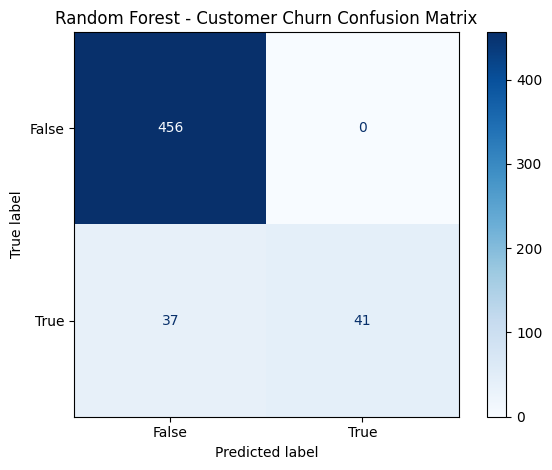

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Customer Churn Confusion Matrix")
plt.tight_layout()
plt.show()

Top 10 features by Random Forest importance:


,Feature,Importance
15,num__Customer service calls,0.120704
3,num__Total day minutes,0.116936
5,num__Total day charge,0.114488
8,num__Total eve charge,0.049599
67,cat__International plan_No,0.048566
68,cat__International plan_Yes,0.047587
6,num__Total eve minutes,0.047583
14,num__Total intl charge,0.040973
12,num__Total intl minutes,0.040726
9,num__Total night minutes,0.038506


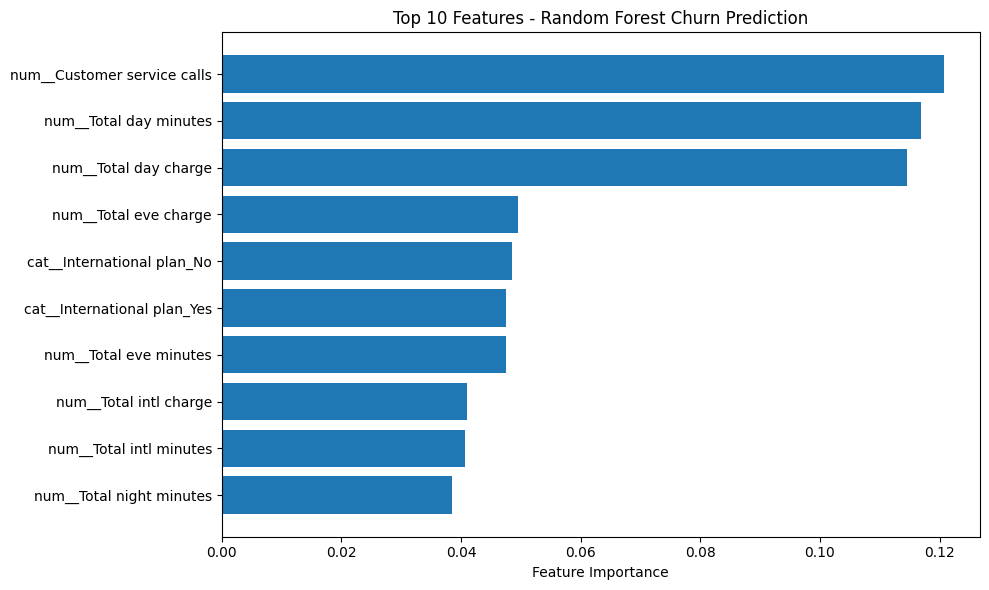

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

preprocessor_fitted = model.named_steps["preprocessor"]
forest = model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": forest.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("Top 10 features by Random Forest importance:")
display(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features - Random Forest Churn Prediction")
plt.tight_layout()
plt.show()